In [16]:
! pip install -q optuna
! pip install -q emoji
! pip install -q iterative-stratification

In [17]:
import pandas as pd
import numpy as np
import tqdm
from sklearn.model_selection import train_test_split
from datasets import Dataset, DatasetDict
from huggingface_hub import login
import torch
from torch import nn
import torch.nn.functional as F
from sklearn.utils.class_weight import compute_class_weight
from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit
import optuna
import ast
import re
import emoji
from transformers.utils import logging as hf_logging
import gc
import shutil
import random
import math
import html
import matplotlib.pyplot as plt
from transformers import AutoTokenizer, Trainer, TrainingArguments, AutoModelForSequenceClassification, EarlyStoppingCallback, TrainerCallback, set_seed
from scipy.special import softmax
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, roc_auc_score, average_precision_score, classification_report
import datasets
import optuna
import sys
from sklearn.metrics import confusion_matrix
from huggingface_hub.utils import disable_progress_bars
from transformers.trainer_callback import PrinterCallback, ProgressCallback
from transformers.utils import logging as hf_logging

hf_logging.set_verbosity_error()          # laporan load model, warning transformers
hf_logging.disable_progress_bar()         # "Writing model shards", "Loading weights"
disable_progress_bars()                   # progress bar download dari Hugging Face Hub
datasets.disable_progress_bars()          # progress bar "Map"
optuna.logging.set_verbosity(optuna.logging.WARNING)   # log bawaan Optuna per trial

In [18]:
df = pd.read_csv(r'/kaggle/input/datasets/evelynuntariady/thesis/explode_dataset_using_latest_cleaned_text.csv')

In [19]:
df.head(1)

,Unnamed: 0.1,Unnamed: 0,text_id,annotator_id,text,topic,is_noise_or_spam_text,toxicity,polarized,profanity_obscenity,...,ethnicity,religion,disability,lgbt,gender,age,domisili,pendidikan terakhir,status pekerjaan,president vote leaning
0,0,0,1-1,7,Wajah Jurnalis Dibalut Perban Saat Melaporkan ...,UNKNOWN,0,0,0,0,...,Minang,Islam,yes,no,F,27,Padang,Sarjana (S1),Bekerja,1


In [20]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 53989 entries, 0 to 53988
Data columns (total 27 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   Unnamed: 0.1                   53989 non-null  int64 
 1   Unnamed: 0                     53989 non-null  int64 
 2   text_id                        53989 non-null  object
 3   annotator_id                   53989 non-null  int64 
 4   text                           53988 non-null  object
 5   topic                          53989 non-null  object
 6   is_noise_or_spam_text          53989 non-null  int64 
 7   toxicity                       53989 non-null  int64 
 8   polarized                      53989 non-null  int64 
 9   profanity_obscenity            53989 non-null  int64 
 10  threat_incitement_to_violence  53989 non-null  int64 
 11  insults                        53989 non-null  int64 
 12  identity_attack                53989 non-null  int64 
 13  s

In [21]:
df = df.drop(columns = ['Unnamed: 0', 'key'])

In [22]:
df['is_noise_or_spam_text'].value_counts()

is_noise_or_spam_text
0    50983
1     3006
Name: count, dtype: int64

In [23]:
df['is_valid'].value_counts()

is_valid
True     53969
False       20
Name: count, dtype: int64

In [24]:
df_main = df[df['is_noise_or_spam_text'] == 0]
df_main = df_main[df_main['is_valid'] == 1]
df_main = df_main.dropna()
df_main.isnull().sum()

Unnamed: 0.1                     0
text_id                          0
annotator_id                     0
text                             0
topic                            0
is_noise_or_spam_text            0
toxicity                         0
polarized                        0
profanity_obscenity              0
threat_incitement_to_violence    0
insults                          0
identity_attack                  0
sexually_explicit                0
cleaned_text                     0
is_valid                         0
ethnicity                        0
religion                         0
disability                       0
lgbt                             0
gender                           0
age                              0
domisili                         0
pendidikan terakhir              0
status pekerjaan                 0
president vote leaning           0
dtype: int64

In [25]:
df_main.info()

<class 'pandas.core.frame.DataFrame'>
Index: 50963 entries, 0 to 53988
Data columns (total 25 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   Unnamed: 0.1                   50963 non-null  int64 
 1   text_id                        50963 non-null  object
 2   annotator_id                   50963 non-null  int64 
 3   text                           50963 non-null  object
 4   topic                          50963 non-null  object
 5   is_noise_or_spam_text          50963 non-null  int64 
 6   toxicity                       50963 non-null  int64 
 7   polarized                      50963 non-null  int64 
 8   profanity_obscenity            50963 non-null  int64 
 9   threat_incitement_to_violence  50963 non-null  int64 
 10  insults                        50963 non-null  int64 
 11  identity_attack                50963 non-null  int64 
 12  sexually_explicit              50963 non-null  int64 
 13  cleane

# Text Cleaning

In [26]:
import sys
sys.path.append("/kaggle/input/datasets/evelynuntariady/thesis")

from preprocess import preprocess_text

In [27]:
from tqdm import tqdm
tqdm.pandas()

SOURCE_COL = "cleaned_text"

df_main["processed_text"] = (
    df_main[SOURCE_COL]
    .fillna("")
    .astype(str)
    .progress_apply(
        lambda x: preprocess_text(x)
    )
)

pd.set_option("display.max_colwidth", 150)
df_main[[SOURCE_COL, "processed_text"]].sample(10, random_state=42)

100%|██████████| 50963/50963 [00:15<00:00, 3371.11it/s]


,cleaned_text,processed_text
17525,China akan mengontrol total penggunaan batu bara dan membatasi proyek-proyek beremisi tinggi untuk meningkatkan kualitas udara. Menurut sebuah ren...,china akan mengontrol total penggunaan batu bara dan membatasi proyek proyek beremisi tinggi untuk meningkatkan kualitas udara. menurut sebuah ren...
14217,Link live streaming Timnas Indonesia U24 vs China Taipei di Asian Games 2022: misi pertahankan puncak klasemen,link live streaming timnas indonesia u vs china taipei di asian games misi pertahankan puncak klasemen
31691,KSTP selalu berbuat ulah dengan merampok dana desa yang harusnya bisa dinikmati masyarakat. Dukung pemberantasan KST Papua agar mereka dibubarkan ...,kstp selalu berbuat ulah dengan merampok dana desa yang harusnya bisa dinikmati masyarakat. dukung pemberantasan kst papua agar mereka dibubarkan ...
21275,Para pemuda Tiongkok (RRC) akan membanjiri posisi ASN di Indonesia,para pemuda tiongkok rrc akan membanjiri posisi asn di indonesia
49010,Film Lightyear dilarang tayang di 14 negara Timur Tengah dan Asia terkait adanya adegan LGBT. Bagaimana menurut kalian?,film lightyear dilarang tayang di negara timur tengah dan asia terkait adanya adegan lgbt. bagaimana menurut kalian?
41155,"Mampus, lembur lagi. Kenapa si bajingan itu bikin saya hampir gila","mampus, lembur lagi. kenapa si bajingan itu bikin saya hampir gila"
34531,"Gila, cincin bagus banget 😭🥹","gila, cincin bagus banget wajah menangis keras wajah menahan air mata"
27729,"Kang tipu, gaes. TKA China pemimpin masa depan. #SMTOWNJAKARTA2023 Cocoki Piting FISIP UI AAA 2023 merangkul rumah produksi","kang tipu, gaes. tka china pemimpin masa depan. smtownjakarta cocoki piting fisip ui aa merangkul rumah produksi"
25577,"Anjir, Miniso antrinya kayak orgil","anjir, miniso antrinya kayak orgil"
49115,Mantan gay yang pertama kali merasakan jatuh cinta... Tapi mencintai istri orang 😬😬😬😬,mantan gay yang pertama kali merasakan jatuh cinta.. tapi mencintai istri orang wajah menyeringai wajah menyeringai wajah menyeringai wajah menyer...


In [28]:
df_main['toxicity'].value_counts()

toxicity
0    41732
1     9231
Name: count, dtype: int64

# Balancing 1/3

In [29]:
pos = df_main[df_main["toxicity"] == 1]
neg = df_main[df_main["toxicity"] == 0].sample(n=3 * len(pos), random_state=42)
df_final = pd.concat([pos, neg]).sample(frac=1, random_state=42).reset_index(drop=True)

In [30]:
df_final['toxicity'].value_counts()

toxicity
0    27693
1     9231
Name: count, dtype: int64

# Stage 1

In [31]:
features = [
    'processed_text',
    'polarized',
    'ethnicity',
    'religion',
    'disability',
    'lgbt',
    'gender',
    'age',
    'domisili',
    'pendidikan terakhir',
    'status pekerjaan',
    'president vote leaning'
]

x = df_final[features]
y = df_final['toxicity']

In [32]:
x_train_full, x_test, y_train_full, y_test = train_test_split(
    x, y, test_size=0.2, stratify=y, random_state=42
)
x_train, x_val, y_train, y_val = train_test_split(
    x_train_full, y_train_full, test_size=0.125, stratify=y_train_full, random_state=42
)

print("Stage 1 split sizes:", {"train": len(x_train), "val": len(x_val), "test": len(x_test)})

Stage 1 split sizes: {'train': 25846, 'val': 3693, 'test': 7385}


In [ ]:
class_weights_s1 = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(y_train),
    y=y_train
)
class_weights_s1 = torch.tensor(class_weights_s1, dtype=torch.float)
print("Stage 1 class weights (class 0, class 1):", class_weights_s1)

In [ ]:
def make_df(x, y):
    df = x.copy()
    df["label"] = y.values
    return df.reset_index(drop=True)

train_df = make_df(x_train, y_train)
val_df = make_df(x_val, y_val)
test_df = make_df(x_test, y_test)

dataset = DatasetDict({
    "train": Dataset.from_pandas(train_df),
    "validation": Dataset.from_pandas(val_df),
    "test": Dataset.from_pandas(test_df),
})
print(dataset)

In [ ]:
tokenizer = AutoTokenizer.from_pretrained("indolem/indobertweet-base-uncased")

In [ ]:
def tokenize_with_feature(batch):
    metadata = []

    for i in range(len(batch["processed_text"])):
        meta = (
            f"Polarisasi: {batch['polarized'][i]}. "
            f"Etnis: {batch['ethnicity'][i]}. "
            f"Agama: {batch['religion'][i]}. "
            f"Disabilitas: {batch['disability'][i]}. "
            f"LGBT: {batch['lgbt'][i]}. "
            f"Gender: {batch['gender'][i]}. "
            f"Usia: {batch['age'][i]}. "
            f"Domisili: {batch['domisili'][i]}. "
            f"Pendidikan: {batch['pendidikan terakhir'][i]}. "
            f"Pekerjaan: {batch['status pekerjaan'][i]}. "
            f"Preferensi politik: {batch['president vote leaning'][i]}."
        )

        metadata.append(meta)

    tokenized = tokenizer(metadata, batch["processed_text"], truncation="only_second", max_length=256, padding="max_length")

    return tokenized

In [ ]:
tokenized_datasets_1 = dataset.map(tokenize_with_feature, batched=True)
tokenized_datasets_1 = tokenized_datasets_1.remove_columns(features)
tokenized_datasets_1 = tokenized_datasets_1.rename_column("label", "labels")
tokenized_datasets_1.set_format("torch")
train_dataset_1 = tokenized_datasets_1["train"]
val_dataset_1 = tokenized_datasets_1["validation"]
test_dataset_1 = tokenized_datasets_1["test"]

In [ ]:
def compute_metrics_s1(eval_pred):
    logits, labels = eval_pred
    probs = softmax(logits, axis=1)[:, 1]
    preds = logits.argmax(axis=1)
    return {
        "accuracy": accuracy_score(labels, preds),
        "precision": precision_score(labels, preds, zero_division=0),
        "recall": recall_score(labels, preds, zero_division=0),
        "f1": f1_score(labels, preds, zero_division=0),
        "f1_macro": f1_score(labels, preds, average="macro", zero_division=0),
        "roc_auc": roc_auc_score(labels, probs),
        "pr_auc": average_precision_score(labels, probs),
    }

In [ ]:
# Trainer that applies class weights to CrossEntropyLoss, used to handle label
# imbalance in Stage 1.
class WeightedTrainerSingleLabel(Trainer):
    def __init__(self, *args, class_weights=None, **kwargs):
        super().__init__(*args, **kwargs)
        self.class_weights = class_weights

    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        logits = outputs.logits
        weight = self.class_weights.to(logits.device) if self.class_weights is not None else None
        loss_fct = nn.CrossEntropyLoss(weight=weight)
        # logits.size(-1) instead of model.config.num_labels: stays correct even if
        # Trainer wraps the model in nn.DataParallel (which doesn't expose .config).
        loss = loss_fct(logits.view(-1, logits.size(-1)), labels.view(-1))
        return (loss, outputs) if return_outputs else loss

In [ ]:
MODEL_NAME = "indolem/indobertweet-base-uncased"
STUDY_NAME = "stage1_balance_polarized_v1"
N_TRIALS = 10
OUTPUT_ROOT = "./optuna_s1"
FINAL_DIR = "./best_s1_optuna"
SEED = 42
LOGGING_STEPS = 10


In [ ]:
# search space
def suggest_params(trial):
    """Nama key = nama parameter Optuna, jadi study.best_params bisa langsung dipakai ulang."""
    return {
        # Prioritas tinggi
        "learning_rate": trial.suggest_float("learning_rate", 8e-6, 6e-5, log=True),
        "warmup_ratio": trial.suggest_float("warmup_ratio", 0.0, 0.2),
        "batch_size": trial.suggest_categorical("batch_size", [8, 16, 32]),
        "num_train_epochs": trial.suggest_int("num_train_epochs", 3, 8),
        "class_weight_alpha": trial.suggest_float("class_weight_alpha", 0.3, 1.0),
        # Prioritas menengah
        "dropout": trial.suggest_float("dropout", 0.1, 0.3),
        "lr_scheduler_type": trial.suggest_categorical("lr_scheduler_type", ["linear", "cosine"]),
        # Prioritas rendah
        "weight_decay": trial.suggest_float("weight_decay", 0.0, 0.1),
        "n_frozen_layers": trial.suggest_int("n_frozen_layers", 0, 6),
        "freeze_embeddings": trial.suggest_categorical("freeze_embeddings", [False, True]),
    }

In [ ]:
def freeze_layer(model, n_freeze, freeze_emb):
    """Bekukan embeddings (opsional) + n_freeze layer encoder."""
    base = model.base_model   # .bert untuk BERT, .roberta untuk XLM-R, dst.
    if freeze_emb:
        for p in base.embeddings.parameters():
            p.requires_grad = False
    for layer in base.encoder.layer[:n_freeze]:
        for p in layer.parameters():
            p.requires_grad = False


class OptunaPruningCallback(TrainerCallback):
    def __init__(self, trial, metric="eval_f1"):
        self.trial = trial
        self.metric = metric

    def on_evaluate(self, args, state, control, metrics=None, **kwargs):
        if not metrics or self.metric not in metrics:
            return
        self.trial.report(metrics[self.metric], step=int(round(state.epoch)))
        if self.trial.should_prune():
            raise optuna.TrialPruned()


def build_trainer(params, out_dir, trial=None):
    """Dipakai oleh objective DAN final training, jadi setup-nya pasti identik."""
    # set_seed mengunci random, numpy, dan torch -> inisialisasi classifier reproducible
    set_seed(SEED)
    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME,
        num_labels=2,
        id2label={0: "non_toxic", 1: "toxic"},
        label2id={"non_toxic": 0, "toxic": 1},
        hidden_dropout_prob=params["dropout"],
        attention_probs_dropout_prob=params["dropout"],
    )
    freeze_layer(model, params["n_frozen_layers"], params["freeze_embeddings"])

    # Warmup dihitung manual dari jumlah step total
    n_gpu = max(1, torch.cuda.device_count())
    steps_per_epoch = math.ceil(len(train_dataset_1) / (params["batch_size"] * n_gpu))
    warmup_steps = int(params["warmup_ratio"] * steps_per_epoch * params["num_train_epochs"])

    args = TrainingArguments(
        output_dir=out_dir,
        num_train_epochs=params["num_train_epochs"],
        per_device_train_batch_size=params["batch_size"],
        per_device_eval_batch_size=64,
        learning_rate=params["learning_rate"],
        warmup_steps=warmup_steps,
        weight_decay=params["weight_decay"],
        lr_scheduler_type=params["lr_scheduler_type"],
        eval_strategy="epoch",
        save_strategy="epoch",
        load_best_model_at_end=True,
        save_only_model=True,
        save_total_limit=1,
        metric_for_best_model="f1",
        greater_is_better=True,
        fp16=torch.cuda.is_available(),
        logging_steps=LOGGING_STEPS,
        disable_tqdm=False,          # progress bar per step + tabel metrik per epoch
        report_to=[],
        seed=SEED,
    )

    callbacks = [EarlyStoppingCallback(early_stopping_patience=2)]
    if trial is not None:
        callbacks.append(OptunaPruningCallback(trial, metric="eval_f1"))

    return WeightedTrainerSingleLabel(
        model=model,
        args=args,
        train_dataset=train_dataset_1,
        eval_dataset=val_dataset_1,
        compute_metrics=compute_metrics_s1,
        class_weights=class_weights_s1 ** params["class_weight_alpha"],   # alpha=1 -> balanced penuh
        callbacks=callbacks,
    )

In [ ]:
def objective_s1(trial):
    params = suggest_params(trial)
    out_dir = f"{OUTPUT_ROOT}/trial_{trial.number}"

    print(f"\n{'=' * 70}\nTrial {trial.number}")
    for k, v in params.items():
        print(f"  {k:20s}: {v:.2e}" if isinstance(v, float) and v < 1e-3 else f"  {k:20s}: {v}")

    trainer = None
    try:
        trainer = build_trainer(params, out_dir, trial)
        trainer.train()
        print(f"Trial {trial.number} selesai | best val F1 = {trainer.state.best_metric:.4f}")
        return trainer.state.best_metric
    except torch.cuda.OutOfMemoryError:
        print(f"Trial {trial.number}: GPU out of memory, dilewati")
        raise optuna.TrialPruned("GPU out of memory")
    finally:
        del trainer
        gc.collect()
        torch.cuda.empty_cache()
        shutil.rmtree(out_dir, ignore_errors=True)

In [ ]:
study_s1 = optuna.create_study(
    direction="maximize",
    study_name=STUDY_NAME,
    sampler=optuna.samplers.TPESampler(seed=SEED),
    pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=2),  # jangan prune di epoch awal, F1 masih dipengaruhi warmup
    storage="sqlite:///optuna_s1.db",
    load_if_exists=True,
)

# Kalau session terputus, rerun sel ini hanya menjalankan sisa trial sampai total N_TRIALS
done = sum(t.state.is_finished() for t in study_s1.trials)
remaining = max(0, N_TRIALS - done)
print(f"Trial selesai: {done} | sisa: {remaining}")
study_s1.optimize(objective_s1, n_trials=remaining, gc_after_trial=True)

In [ ]:
print(f"Best trial #{study_s1.best_trial.number} | val F1 = {study_s1.best_value:.4f}")
for k, v in study_s1.best_params.items():
    print(f"  {k:20s}: {v}")

trials_df = study_s1.trials_dataframe(attrs=("number", "value", "state", "params"))
trials_df.columns = [c.replace("params_", "") for c in trials_df.columns]
display(trials_df.sort_values("value", ascending=False).head(10)
        .round({"value": 4, "class_weight_alpha": 4, "dropout": 4, "warmup_ratio": 4, "weight_decay": 4})
        .style.format({"learning_rate": "{:.2e}"}))

In [ ]:
optuna.visualization.plot_param_importances(study_s1).show()
optuna.visualization.plot_optimization_history(study_s1).show()

In [ ]:
trainer_s1 = build_trainer(study_s1.best_params, FINAL_DIR)
trainer_s1.train()
model_s1 = trainer_s1.model

trainer_s1.save_model(FINAL_DIR)
tokenizer.save_pretrained(FINAL_DIR)
print(f"Final model tersimpan di {FINAL_DIR}")

In [ ]:
history_s1 = trainer_s1.state.log_history

# Training loss rata-rata per epoch
train_logs_s1 = [x for x in history_s1 if 'loss' in x and 'eval_loss' not in x]
train_epochs_s1 = [x['epoch'] for x in train_logs_s1]
train_losses_s1 = [x['loss'] for x in train_logs_s1]

epoch_numbers_s1 = sorted(set(int(np.ceil(e)) for e in train_epochs_s1))
avg_train_loss_s1 = [
    np.mean([l for e, l in zip(train_epochs_s1, train_losses_s1) if int(np.ceil(e)) == ep])
    for ep in epoch_numbers_s1
]

# Validation loss per epoch (ambil yang pertama tiap epoch)
val_loss_by_epoch_s1 = {}
for x in history_s1:
    if 'eval_loss' in x:
        ep = int(round(x['epoch']))
        if ep > 0 and ep not in val_loss_by_epoch_s1:
            val_loss_by_epoch_s1[ep] = x['eval_loss']
val_epochs_s1 = sorted(val_loss_by_epoch_s1)
val_losses_s1 = [val_loss_by_epoch_s1[ep] for ep in val_epochs_s1]

plt.figure(figsize=(10, 6))
plt.plot(epoch_numbers_s1, avg_train_loss_s1, marker='o', label='Training Loss')
plt.plot(val_epochs_s1, val_losses_s1, marker='o', label='Validation Loss')
plt.title('Training vs Validation Loss - Stage 1 (nusabert)')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
pred1 = trainer_s1.predict(test_dataset_1)
pred_label1 = pred1.predictions.argmax(axis=1)

probs1_test = torch.softmax(torch.tensor(pred1.predictions), dim=-1)[:, 1].numpy()

print("Stage 1 classification report -- test set:")
print(classification_report(y_test, pred_label1))

In [ ]:
cm_s1 = confusion_matrix(y_test, pred_label1, labels=[0, 1])

cm_df_s1 = pd.DataFrame(
    cm_s1,
    index=["Actual Non-Toxic (0)", "Actual Toxic (1)"],
    columns=["Predicted Non-Toxic (0)", "Predicted Toxic (1)"]
)

cm_df_s1

In [ ]:
print(f"ROC-AUC (test): {roc_auc_score(y_test, probs1_test):.4f}")
print(f"PR-AUC  (test): {average_precision_score(y_test, probs1_test):.4f}\n")

In [ ]:
# import shutil

# shutil.make_archive(
#     "/content/best_s1_optuna",
#     "zip",
#     root_dir="/content",
#     base_dir="best_s1_optuna"
# )

# print("ZIP berhasil dibuat: /content/best_s1_optuna.zip")

# Stage 2

In [33]:
df_toxic = df_main[df_main["toxicity"] == 1].copy()

In [34]:
# This variant keeps ALL 5 labels.
LABEL_COLS = [
    "insults",
    "identity_attack",
    "threat_incitement_to_violence",
    "profanity_obscenity",
    "sexually_explicit",
]

features = [
    'processed_text',
    'ethnicity',
    'religion',
    'disability',
    'lgbt',
    'gender',
    'age',
    'domisili',
    'pendidikan terakhir',
    'status pekerjaan',
    'president vote leaning'
]

x2 = df_toxic[features]
y2 = df_toxic[LABEL_COLS]

In [35]:
# Padanan stratify=y di Stage 1 untuk multilabel: iterative stratification menjaga
# proporsi tiap label (termasuk label langka) tetap mirip di train/val/test.
def ml_train_test_split(x, y, test_size, random_state=42):
    msss = MultilabelStratifiedShuffleSplit(n_splits=1, test_size=test_size, random_state=random_state)
    train_idx, test_idx = next(msss.split(x, y.values))
    return x.iloc[train_idx], x.iloc[test_idx], y.iloc[train_idx], y.iloc[test_idx]

x2_train_full, x2_test, y2_train_full, y2_test = ml_train_test_split(x2, y2, test_size=0.2, random_state=42)
x2_train, x2_val, y2_train, y2_val = ml_train_test_split(x2_train_full, y2_train_full, test_size=0.125, random_state=42)

print("Stage 2 split sizes:", {"train": len(x2_train), "val": len(x2_val), "test": len(x2_test)})
print(pd.DataFrame({"train": y2_train.sum(), "val": y2_val.sum(), "test": y2_test.sum()}))

Stage 2 split sizes: {'train': 6461, 'val': 923, 'test': 1847}
                               train  val  test
insults                         3035  433   868
identity_attack                 2776  396   794
threat_incitement_to_violence    829  118   237
profanity_obscenity             1195  171   342
sexually_explicit                269   38    77


In [36]:
# Random oversampling of minority-label rows for Stage 2 (multi-label). For each label
# whose positive count is below the most frequent label's count, duplicate (with
# replacement) rows carrying that label until the gap is filled. Only the TRAIN split is
# resampled -- val/test keep their natural distribution.
def oversample_multilabel(df, label_cols, random_state=42):
    max_count = df[label_cols].sum().max()
    parts = [df]
    for col in label_cols:
        col_count = df[col].sum()
        n_needed = int(max_count - col_count)
        if n_needed > 0:
            minority_rows = df[df[col] == 1]
            if len(minority_rows) > 0:
                parts.append(minority_rows.sample(n=n_needed, replace=True, random_state=random_state))
    balanced = pd.concat(parts).sample(frac=1, random_state=random_state).reset_index(drop=True)
    return balanced

In [37]:
# Oversample the TRAIN split only. val/test keep their natural distribution.
train_df_s2 = pd.concat([x2_train, y2_train], axis=1)
print("Before oversampling:", {c: int(train_df_s2[c].sum()) for c in LABEL_COLS})
train_df_s2 = oversample_multilabel(train_df_s2, LABEL_COLS, random_state=42)
print("After oversampling:", {c: int(train_df_s2[c].sum()) for c in LABEL_COLS})

x2_train, y2_train = train_df_s2[features], train_df_s2[LABEL_COLS]

Before oversampling: {'insults': 3035, 'identity_attack': 2776, 'threat_incitement_to_violence': 829, 'profanity_obscenity': 1195, 'sexually_explicit': 269}
After oversampling: {'insults': 4679, 'identity_attack': 4308, 'threat_incitement_to_violence': 3249, 'profanity_obscenity': 4320, 'sexually_explicit': 3229}


In [38]:
def make_df_s2(x, y):
    df = x.copy()
    df["label"] = y.astype(float).values.tolist()   # float: BCEWithLogitsLoss butuh label float
    return df.reset_index(drop=True)

train_df_s2 = make_df_s2(x2_train, y2_train)
val_df_s2 = make_df_s2(x2_val, y2_val)
test_df_s2 = make_df_s2(x2_test, y2_test)

dataset_s2 = DatasetDict({
    "train": Dataset.from_pandas(train_df_s2),
    "validation": Dataset.from_pandas(val_df_s2),
    "test": Dataset.from_pandas(test_df_s2),
})
print(dataset_s2)

DatasetDict({
    train: Dataset({
        features: ['processed_text', 'ethnicity', 'religion', 'disability', 'lgbt', 'gender', 'age', 'domisili', 'pendidikan terakhir', 'status pekerjaan', 'president vote leaning', 'label'],
        num_rows: 13532
    })
    validation: Dataset({
        features: ['processed_text', 'ethnicity', 'religion', 'disability', 'lgbt', 'gender', 'age', 'domisili', 'pendidikan terakhir', 'status pekerjaan', 'president vote leaning', 'label'],
        num_rows: 923
    })
    test: Dataset({
        features: ['processed_text', 'ethnicity', 'religion', 'disability', 'lgbt', 'gender', 'age', 'domisili', 'pendidikan terakhir', 'status pekerjaan', 'president vote leaning', 'label'],
        num_rows: 1847
    })
})


In [39]:
tokenizer_s2 = AutoTokenizer.from_pretrained("indolem/indobertweet-base-uncased")

In [40]:
def tokenize_s2(batch):
    metadata = []

    for i in range(len(batch["processed_text"])):
        meta = (
            f"Etnis: {batch['ethnicity'][i]}. "
            f"Agama: {batch['religion'][i]}. "
            f"Disabilitas: {batch['disability'][i]}. "
            f"LGBT: {batch['lgbt'][i]}. "
            f"Gender: {batch['gender'][i]}. "
            f"Usia: {batch['age'][i]}. "
            f"Domisili: {batch['domisili'][i]}. "
            f"Pendidikan: {batch['pendidikan terakhir'][i]}. "
            f"Pekerjaan: {batch['status pekerjaan'][i]}. "
            f"Preferensi politik: {batch['president vote leaning'][i]}."
        )

        metadata.append(meta)

    return tokenizer_s2(metadata, batch["processed_text"], truncation="only_second", max_length=256, padding="max_length")

tokenized_datasets_2 = dataset_s2.map(tokenize_s2, batched=True)
tokenized_datasets_2 = tokenized_datasets_2.remove_columns(features)
tokenized_datasets_2 = tokenized_datasets_2.rename_column("label", "labels")
tokenized_datasets_2.set_format("torch")

train_dataset_2 = tokenized_datasets_2["train"]
val_dataset_2 = tokenized_datasets_2["validation"]
test_dataset_2 = tokenized_datasets_2["test"]

print(tokenizer_s2.decode(train_dataset_2[0]["input_ids"], skip_special_tokens=True))
print(train_dataset_2[0]["labels"])

etnis : batak. agama : kepercayaan lokal. disabilitas : no. lgbt : no. gender : f. usia : 29. domisili : medan. pendidikan : sarjana ( s1 ). pekerjaan : bekerja. preferensi politik : 3. para pemuda tiongkok rrc akan membanjiri posisi asn di indonesia.
tensor([0., 1., 0., 0., 0.])


In [41]:
def safe_auc(score_fn, labels, probs):
    """AUC macro; NaN kalau ada label yang di split ini cuma punya satu kelas."""
    try:
        return score_fn(labels, probs, average="macro")
    except ValueError:
        return float("nan")


def compute_metrics_s2(eval_pred):
    logits, labels = eval_pred
    probs = 1 / (1 + np.exp(-logits))   # sigmoid per label
    preds = (probs >= 0.5).astype(int)
    return {
        "accuracy": accuracy_score(labels, preds),   # exact match (subset accuracy)
        "precision_micro": precision_score(labels, preds, average="micro", zero_division=0),
        "recall_micro": recall_score(labels, preds, average="micro", zero_division=0),
        "f1_micro": f1_score(labels, preds, average="micro", zero_division=0),
        "f1_macro": f1_score(labels, preds, average="macro", zero_division=0),
        "roc_auc": safe_auc(roc_auc_score, labels, probs),
        "pr_auc": safe_auc(average_precision_score, labels, probs),
    }

In [42]:
MODEL_NAME = "indolem/indobertweet-base-uncased"
STUDY_NAME_S2 = "stage2_oversampling_s2_v1"
N_TRIALS_S2 = 10
OUTPUT_ROOT_S2 = "./optuna_s2"
FINAL_DIR_S2 = "./best_s2_optuna"
SEED = 42
LOGGING_STEPS = 10
METRIC_S2 = "f1_macro"   # macro: setiap label (termasuk yang langka) berbobot sama

In [43]:
# search space
def suggest_params_s2(trial):
    """Nama key = nama parameter Optuna, jadi study.best_params bisa langsung dipakai ulang."""
    return {
        # Prioritas tinggi
        "learning_rate": trial.suggest_float("learning_rate", 8e-6, 6e-5, log=True),
        "warmup_ratio": trial.suggest_float("warmup_ratio", 0.0, 0.2),
        "batch_size": trial.suggest_categorical("batch_size", [8, 16, 32]),
        "num_train_epochs": trial.suggest_int("num_train_epochs", 3, 8),
        "class_weight_alpha": trial.suggest_float("class_weight_alpha", 0.3, 1.0),
        # Prioritas menengah
        "dropout": trial.suggest_float("dropout", 0.1, 0.3),
        "lr_scheduler_type": trial.suggest_categorical("lr_scheduler_type", ["linear", "cosine"]),
        # Prioritas rendah
        "weight_decay": trial.suggest_float("weight_decay", 0.0, 0.1),
        "n_frozen_layers": trial.suggest_int("n_frozen_layers", 0, 6),
        "freeze_embeddings": trial.suggest_categorical("freeze_embeddings", [False, True]),
    }

In [44]:
def freeze_layer(model, n_freeze, freeze_emb):
    """Bekukan embeddings (opsional) + n_freeze layer encoder."""
    base = model.base_model   # .bert untuk BERT, .roberta untuk XLM-R, dst.
    if freeze_emb:
        for p in base.embeddings.parameters():
            p.requires_grad = False
    for layer in base.encoder.layer[:n_freeze]:
        for p in layer.parameters():
            p.requires_grad = False


class OptunaPruningCallback(TrainerCallback):
    def __init__(self, trial, metric="eval_f1"):
        self.trial = trial
        self.metric = metric

    def on_evaluate(self, args, state, control, metrics=None, **kwargs):
        if not metrics or self.metric not in metrics:
            return
        self.trial.report(metrics[self.metric], step=int(round(state.epoch)))
        if self.trial.should_prune():
            raise optuna.TrialPruned()


def build_trainer_s2(params, out_dir, trial=None):
    """Dipakai oleh objective DAN final training, jadi setup-nya pasti identik."""
    # set_seed mengunci random, numpy, dan torch -> inisialisasi classifier reproducible
    set_seed(SEED)
    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME,
        num_labels=len(LABEL_COLS),
        problem_type="multi_label_classification",
        id2label={i: l for i, l in enumerate(LABEL_COLS)},
        label2id={l: i for i, l in enumerate(LABEL_COLS)},
        hidden_dropout_prob=params["dropout"],
        attention_probs_dropout_prob=params["dropout"],
    )
    freeze_layer(model, params["n_frozen_layers"], params["freeze_embeddings"])

    # Warmup dihitung manual dari jumlah step total
    n_gpu = max(1, torch.cuda.device_count())
    steps_per_epoch = math.ceil(len(train_dataset_2) / (params["batch_size"] * n_gpu))
    warmup_steps = int(params["warmup_ratio"] * steps_per_epoch * params["num_train_epochs"])

    args = TrainingArguments(
        output_dir=out_dir,
        num_train_epochs=params["num_train_epochs"],
        per_device_train_batch_size=params["batch_size"],
        per_device_eval_batch_size=64,
        learning_rate=params["learning_rate"],
        warmup_steps=warmup_steps,
        eval_strategy="epoch",
        save_strategy="epoch",
        load_best_model_at_end=True,
        save_only_model=True,
        save_total_limit=1,
        metric_for_best_model=METRIC_S2,
        greater_is_better=True,
        fp16=torch.cuda.is_available(),
        logging_steps=LOGGING_STEPS,
        disable_tqdm=False,          # progress bar per step + tabel metrik per epoch
        report_to=[],
        seed=SEED,
    )

    callbacks = [EarlyStoppingCallback(early_stopping_patience=2)]
    if trial is not None:
        callbacks.append(OptunaPruningCallback(trial, metric=f"eval_{METRIC_S2}"))

    # Trainer biasa: problem_type multi_label -> BCEWithLogitsLoss tanpa weighting,
    # imbalance ditangani oleh oversampling saja.
    return Trainer(
        model=model,
        args=args,
        train_dataset=train_dataset_2,
        eval_dataset=val_dataset_2,
        compute_metrics=compute_metrics_s2,
        callbacks=callbacks,
    )

In [45]:
def objective_s2(trial):
    params = suggest_params_s2(trial)
    out_dir = f"{OUTPUT_ROOT_S2}/trial_{trial.number}"

    print(f"\n{'=' * 70}\nTrial {trial.number}")
    for k, v in params.items():
        print(f"  {k:20s}: {v:.2e}" if isinstance(v, float) and v < 1e-3 else f"  {k:20s}: {v}")

    trainer = None
    try:
        trainer = build_trainer_s2(params, out_dir, trial)
        trainer.train()
        print(f"Trial {trial.number} selesai | best val {METRIC_S2} = {trainer.state.best_metric:.4f}")
        return trainer.state.best_metric
    except torch.cuda.OutOfMemoryError:
        print(f"Trial {trial.number}: GPU out of memory, dilewati")
        raise optuna.TrialPruned("GPU out of memory")
    finally:
        del trainer
        gc.collect()
        torch.cuda.empty_cache()
        shutil.rmtree(out_dir, ignore_errors=True)

In [46]:
study_s2 = optuna.create_study(
    direction="maximize",
    study_name=STUDY_NAME_S2,
    sampler=optuna.samplers.TPESampler(seed=SEED),
    pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=2),  # jangan prune di epoch awal, F1 masih dipengaruhi warmup
    storage="sqlite:///optuna_s2.db",    # file terpisah dari stage 1
    load_if_exists=True,
)

# Kalau session terputus, rerun sel ini hanya menjalankan sisa trial sampai total N_TRIALS_S2
done = sum(t.state.is_finished() for t in study_s2.trials)
remaining = max(0, N_TRIALS_S2 - done)
print(f"Trial selesai: {done} | sisa: {remaining}")
study_s2.optimize(objective_s2, n_trials=remaining, gc_after_trial=True)

Trial selesai: 0 | sisa: 10

Trial 0
  learning_rate       : 1.70e-05
  warmup_ratio        : 0.19014286128198324
  batch_size          : 8
  num_train_epochs    : 3
  class_weight_alpha  : 0.3406585285177396
  dropout             : 0.273235229154987
  lr_scheduler_type   : cosine
  weight_decay        : 0.0020584494295802446
  n_frozen_layers     : 6
  freeze_embeddings   : False


/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Epoch,Training Loss,Validation Loss,Accuracy,Precision Micro,Recall Micro,F1 Micro,F1 Macro,Roc Auc,Pr Auc
1,0.964087,0.879783,0.332611,0.610405,0.456747,0.522514,0.502896,0.788347,0.583188
2,0.796285,0.847678,0.375948,0.614286,0.520761,0.563670,0.545900,0.831319,0.656846
3,0.814277,0.808191,0.398700,0.632058,0.600346,0.615794,0.584844,0.837828,0.660820


/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Trial 0 selesai | best val f1_macro = 0.5848

Trial 1
  learning_rate       : 1.15e-05
  warmup_ratio        : 0.03668090197068676
  batch_size          : 16
  num_train_epochs    : 4
  class_weight_alpha  : 0.7282970263056656
  dropout             : 0.12789877213040837
  lr_scheduler_type   : cosine
  weight_decay        : 0.0456069984217036
  n_frozen_layers     : 5
  freeze_embeddings   : True


...

Trial 8 selesai | best val f1_macro = 0.6490

Trial 9
  learning_rate       : 4.16e-05
  warmup_ratio        : 0.1721461166512687
  batch_size          : 16
  num_train_epochs    : 4
  class_weight_alpha  : 0.38390575713357794
  dropout             : 0.1675230342807256
  lr_scheduler_type   : linear
  weight_decay        : 0.05187906217433661
  n_frozen_layers     : 4
  freeze_embeddings   : True


/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Epoch,Training Loss,Validation Loss,Accuracy,Precision Micro,Recall Micro,F1 Micro,F1 Macro,Roc Auc,Pr Auc
1,0.781648,0.791488,0.431203,0.665717,0.606401,0.634676,0.603338,0.839334,0.649974
2,0.564210,0.757568,0.442037,0.650888,0.666090,0.658401,0.623039,0.858352,0.690319
3,0.451295,0.800409,0.465872,0.660714,0.672145,0.666381,0.630359,0.861623,0.686349
4,0.410653,0.778669,0.471289,0.665012,0.695502,0.679915,0.643995,0.860082,0.692895


/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Trial 9 selesai | best val f1_macro = 0.6440


In [ ]:
print(f"Best trial #{study_s2.best_trial.number} | val {METRIC_S2} = {study_s2.best_value:.4f}")
for k, v in study_s2.best_params.items():
    print(f"  {k:20s}: {v}")

trials_df_s2 = study_s2.trials_dataframe(attrs=("number", "value", "state", "params"))
trials_df_s2.columns = [c.replace("params_", "") for c in trials_df_s2.columns]
display(trials_df_s2.sort_values("value", ascending=False).head(10)
        .round({"value": 4, "dropout": 4, "warmup_ratio": 4, "weight_decay": 4})
        .style.format({"learning_rate": "{:.2e}"}))

Best trial #5 | val f1_macro = 0.6544
  learning_rate       : 3.791852807074367e-05
  warmup_ratio        : 0.03974313630683449
  batch_size          : 16
  num_train_epochs    : 7
  class_weight_alpha  : 0.8398892426801621
  dropout             : 0.11480893034681808
  lr_scheduler_type   : linear
  weight_decay        : 0.08631034258755936
  n_frozen_layers     : 4
  freeze_embeddings   : False


,number,value,state,batch_size,class_weight_alpha,dropout,freeze_embeddings,learning_rate,lr_scheduler_type,n_frozen_layers,num_train_epochs,warmup_ratio,weight_decay
5,5,0.654400,COMPLETE,16,0.839889,0.114800,False,3.79e-05,linear,4,7,0.039700,0.086300
8,8,0.649000,COMPLETE,16,0.924791,0.207900,True,5.21e-05,cosine,0,4,0.161600,0.031800
9,9,0.644000,COMPLETE,16,0.383906,0.167500,True,4.16e-05,linear,4,4,0.172100,0.051900
2,2,0.635300,COMPLETE,8,0.975942,0.261700,True,2.64e-05,linear,3,8,0.009300,0.068400
1,1,0.612600,COMPLETE,16,0.728297,0.127900,True,1.15e-05,cosine,5,4,0.036700,0.045600
7,7,0.608200,PRUNED,16,0.935297,0.149900,False,8.42e-06,cosine,0,6,0.021600,0.022900
3,3,0.601800,COMPLETE,16,0.682697,0.137000,True,8.57e-06,linear,6,6,0.181900,0.093900
0,0,0.584800,COMPLETE,8,0.340659,0.273200,False,1.70e-05,cosine,6,3,0.190100,0.002100
4,4,0.566900,COMPLETE,32,0.880116,0.171400,True,9.56e-06,cosine,5,4,0.039200,0.014100
6,6,0.532600,PRUNED,32,0.383716,0.242600,False,1.50e-05,linear,3,5,0.065000,0.077100


In [ ]:
optuna.visualization.plot_param_importances(study_s2).show()
optuna.visualization.plot_optimization_history(study_s2).show()

In [ ]:
trainer_s2 = build_trainer_s2(study_s2.best_params, FINAL_DIR_S2)
trainer_s2.train()
model_s2 = trainer_s2.model

trainer_s2.save_model(FINAL_DIR_S2)
tokenizer_s2.save_pretrained(FINAL_DIR_S2)
print(f"Final model tersimpan di {FINAL_DIR_S2}")

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning:

Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.



Epoch,Training Loss,Validation Loss,Accuracy,Precision Micro,Recall Micro,F1 Micro,F1 Macro,Roc Auc,Pr Auc
1,0.663591,0.765730,0.436620,0.667274,0.633218,0.649800,0.628778,0.856330,0.686974
2,0.458351,0.730611,0.484290,0.684662,0.691176,0.687904,0.652679,0.864534,0.698241
3,0.340089,0.795336,0.481040,0.683160,0.680796,0.681976,0.648063,0.860399,0.680343
4,0.284085,0.847553,0.487541,0.685374,0.697232,0.691252,0.662553,0.855170,0.671882
5,0.184151,0.898978,0.491874,0.690784,0.693772,0.692274,0.658589,0.856458,0.678265
6,0.156057,0.910646,0.501625,0.706454,0.691176,0.698732,0.656822,0.853843,0.677219


/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning:

Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning:

Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning:

Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning:

Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning:

Was asked to gather along dimension 0, but all input tensors were scalars; will instead un

Final model tersimpan di ./best_s2_optuna


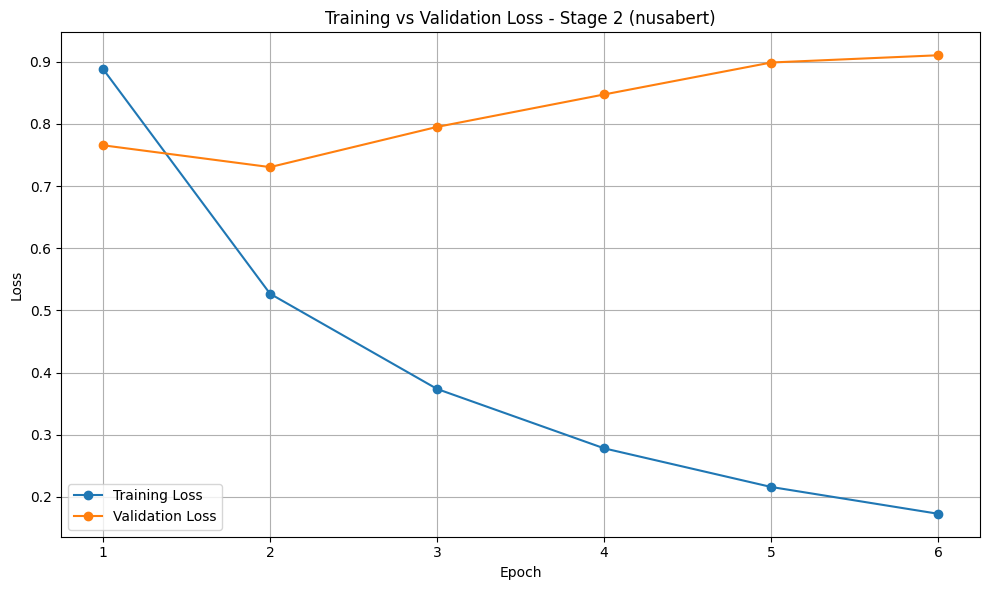

In [ ]:
history_s2 = trainer_s2.state.log_history

# Training loss rata-rata per epoch
train_logs_s2 = [x for x in history_s2 if 'loss' in x and 'eval_loss' not in x]
train_epochs_s2 = [x['epoch'] for x in train_logs_s2]
train_losses_s2 = [x['loss'] for x in train_logs_s2]

epoch_numbers_s2 = sorted(set(int(np.ceil(e)) for e in train_epochs_s2))
avg_train_loss_s2 = [
    np.mean([l for e, l in zip(train_epochs_s2, train_losses_s2) if int(np.ceil(e)) == ep])
    for ep in epoch_numbers_s2
]

# Validation loss per epoch (ambil yang pertama tiap epoch)
val_loss_by_epoch_s2 = {}
for x in history_s2:
    if 'eval_loss' in x:
        ep = int(round(x['epoch']))
        if ep > 0 and ep not in val_loss_by_epoch_s2:
            val_loss_by_epoch_s2[ep] = x['eval_loss']
val_epochs_s2 = sorted(val_loss_by_epoch_s2)
val_losses_s2 = [val_loss_by_epoch_s2[ep] for ep in val_epochs_s2]

plt.figure(figsize=(10, 6))
plt.plot(epoch_numbers_s2, avg_train_loss_s2, marker='o', label='Training Loss')
plt.plot(val_epochs_s2, val_losses_s2, marker='o', label='Validation Loss')
plt.title('Training vs Validation Loss - Stage 2 (nusabert)')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
pred2 = trainer_s2.predict(test_dataset_2)
probs2_test = 1 / (1 + np.exp(-pred2.predictions))   # sigmoid per label
y2_true = pred2.label_ids.astype(int)

pred_label2 = (probs2_test >= 0.5).astype(int)

print("Stage 2 classification report -- test set:")
print(classification_report(y2_true, pred_label2, target_names=LABEL_COLS, zero_division=0))


/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning:

Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.



Stage 2 classification report -- test set:
                               precision    recall  f1-score   support

                      insults       0.70      0.69      0.69       868
              identity_attack       0.79      0.68      0.73       794
threat_incitement_to_violence       0.55      0.70      0.62       237
          profanity_obscenity       0.50      0.71      0.58       342
            sexually_explicit       0.58      0.62      0.60        77

                    micro avg       0.66      0.69      0.68      2318
                    macro avg       0.62      0.68      0.65      2318
                 weighted avg       0.68      0.69      0.68      2318
                  samples avg       0.66      0.68      0.65      2318



In [ ]:
cm_results = []

for i, label in enumerate(LABEL_COLS):
    tn, fp, fn, tp = confusion_matrix(
        y2_true[:, i],
        pred_label2[:, i],
        labels=[0, 1]
    ).ravel()
    cm_results.append({"Label": label, "TN": tn, "FP": fp, "FN": fn, "TP": tp})

cm_s2 = pd.DataFrame(cm_results)
cm_s2

,Label,TN,FP,FN,TP
0,insults,716,263,268,600
1,identity_attack,912,141,251,543
2,threat_incitement_to_violence,1475,135,71,166
3,profanity_obscenity,1260,245,100,242
4,sexually_explicit,1735,35,29,48


In [ ]:
# import shutil

# shutil.make_archive(
#     "/content/best_s2_optuna",
#     "zip",
#     root_dir="/content",
#     base_dir="best_s2_optuna"
# )

# print("ZIP berhasil dibuat: /content/best_s2_optuna.zip")

In [ ]:
# import shutil

# shutil.make_archive(
#     "/kaggle/working/best_s1_optuna",
#     "zip",
#     root_dir="/kaggle/working",
#     base_dir="best_s1_optuna"
# )

# print("ZIP berhasil dibuat: /kaggle/working/best_s1_optuna.zip")

In [ ]:
import shutil

shutil.make_archive(
    "/kaggle/working/best_s2_optuna",
    "zip",
    root_dir="/kaggle/working",
    base_dir="best_s2_optuna"
)

print("ZIP berhasil dibuat: /kaggle/working/best_s2_optuna.zip")

ZIP berhasil dibuat: /kaggle/working/best_s2_optuna.zip
